# Data pipeline and EDA — US2, US3, US4, US5

**Jira:** SCRUM-7, SCRUM-8, SCRUM-9, SCRUM-10 · **Sprint 1–2**

Builds the modelling dataset from the raw OULAD archive and runs the
exploratory analysis. Same logic as `src/data_pipeline.py`.

Put the seven OULAD CSV files in `data/raw/` and run this notebook from
the `notebooks/` folder.

### Traps in the raw archive that this notebook handles

1. missing values are written as `?`, not as empty cells
2. `studentVle.csv` has 10.6M rows and must be read in chunks
3. the key is `(code_module, code_presentation, id_student)`, not `id_student`
4. `nunique` cannot be summed across chunks, so rows are aggregated once
5. weeks with no activity must be zeros, not missing rows
6. exams with no date happen at the end of the presentation
7. `date_unregistration` leaks the target and must never be a feature
8. students who left before the prediction week cannot be warned

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)

RAW = '../data/raw/'
OUT = '../data/processed/'
os.makedirs(OUT, exist_ok=True)

NA_VALUES = ['?']

# AAA was dropped: 711 students and a base at-risk rate of 0.25 against 0.41
# for BBB and 0.50 for CCC, which makes the decision threshold unstable.
# CCC has two exams of weight 100 each; the rescaling below divides by the
# sum within the group, so they correctly become 20 + 20 = 40.
MODULES = ['BBB', 'CCC']

PREDICTION_WEEK = 6          # nothing after day 41 enters the features
CUTOFF_DAY = PREDICTION_WEEK * 7

# Project assumption: the grade is 60% prefinal (TMA + CMA) and 40% final
# exam. OULAD scores continuous assessment and the exam separately, so this
# split is ours.
PREFINAL_WEIGHT = 60

KEY = ['code_module', 'code_presentation', 'id_student']

## US2 — load the OULAD tables

In [15]:
import zipfile, os
os.makedirs('../data/raw', exist_ok=True)
with zipfile.ZipFile(os.path.expanduser('~/Downloads/open+university+learning+analytics+dataset.zip')) as z:
    z.extractall('../data/raw')
print(sorted(os.listdir('../data/raw')))

['OULAD.names', 'assessments.csv', 'courses.csv', 'studentAssessment.csv', 'studentInfo.csv', 'studentRegistration.csv', 'studentVle.csv', 'vle.csv']


In [42]:
import os
print(sorted(os.listdir('../data/raw')))

['OULAD.names', 'assessments.csv', 'courses.csv', 'studentAssessment.csv', 'studentInfo.csv', 'studentRegistration.csv', 'studentVle.csv', 'vle.csv']


In [16]:
courses = pd.read_csv(RAW + 'courses.csv', na_values=NA_VALUES)
assessments = pd.read_csv(RAW + 'assessments.csv', na_values=NA_VALUES)
student_info = pd.read_csv(RAW + 'studentInfo.csv', na_values=NA_VALUES)
student_reg = pd.read_csv(RAW + 'studentRegistration.csv', na_values=NA_VALUES)
student_assess = pd.read_csv(RAW + 'studentAssessment.csv', na_values=NA_VALUES)

courses = courses[courses.code_module.isin(MODULES)]
assessments = assessments[assessments.code_module.isin(MODULES)]
student_info = student_info[student_info.code_module.isin(MODULES)]
student_reg = student_reg[student_reg.code_module.isin(MODULES)]
student_assess = student_assess[student_assess.id_assessment.isin(assessments.id_assessment)]

print('studentInfo', student_info.shape)
student_info.head(3)

studentInfo (12343, 12)


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
748,BBB,2013B,23629,F,East Anglian Region,Lower Than A Level,20-30%,0-35,2,60,N,Fail
749,BBB,2013B,25107,F,East Anglian Region,Lower Than A Level,20-30%,0-35,0,120,N,Pass
750,BBB,2013B,27891,M,Scotland,Lower Than A Level,0-10%,0-35,2,120,Y,Withdrawn


In [19]:
# Exams with no date take place at the end of the presentation
assessments = assessments.merge(
    courses[['code_module', 'code_presentation', 'module_presentation_length']],
    on=['code_module', 'code_presentation'], how='left')
assessments['date'] = assessments['date'].fillna(assessments['module_presentation_length'])
assessments = assessments.drop(columns='module_presentation_length')

base = student_info.merge(student_reg, on=KEY, how='left')
base = base.merge(courses, on=['code_module', 'code_presentation'], how='left')
print('base table', base.shape)

base table (12343, 15)


## US3 — weekly activity from the click log

`studentVle.csv` is 450 MB. We read it in chunks, keep only the chosen
modules and only days 0..41, then aggregate **once** at the end.

Aggregating inside every chunk and summing the results would count the same
day or material twice when a student-week is split across two chunks —
`nunique` cannot be added up.

In [22]:
last_day = PREDICTION_WEEK * 7 - 1
use_cols = ['code_module', 'code_presentation', 'id_student',
            'id_site', 'date', 'sum_click']

kept = []
for chunk in pd.read_csv(RAW + 'studentVle.csv', usecols=use_cols,
                         chunksize=1_000_000, na_values=NA_VALUES):
    chunk = chunk[chunk.code_module.isin(MODULES)]
    chunk = chunk[chunk['date'].between(0, last_day)]
    if not chunk.empty:
        kept.append(chunk)

raw_rows = pd.concat(kept, ignore_index=True)
raw_rows['week'] = raw_rows['date'] // 7
print(f'{len(raw_rows):,} click records kept')

773,521 click records kept


In [23]:
weekly = raw_rows.groupby(KEY + ['week']).agg(
    total_clicks=('sum_click', 'sum'),
    active_days=('date', 'nunique'),
    distinct_materials=('id_site', 'nunique'),
).reset_index()

# A week with no activity must be a zero, not a missing row. Otherwise a
# student who worked one week out of six looks the same on averages as a
# student who worked all six.
students = weekly[KEY].drop_duplicates()
weeks = pd.DataFrame({'week': range(PREDICTION_WEEK)})
grid = students.merge(weeks, how='cross')
weekly = grid.merge(weekly, on=KEY + ['week'], how='left').fillna(
    {'total_clicks': 0, 'active_days': 0, 'distinct_materials': 0})

print(f'{len(weekly)} rows for {weekly.id_student.nunique()} students')
weekly.head()

61494 rows for 10008 students


,code_module,code_presentation,id_student,week,total_clicks,active_days,distinct_materials
0,BBB,2013B,23629,0,23.0,2.0,6.0
1,BBB,2013B,23629,1,5.0,1.0,2.0
2,BBB,2013B,23629,2,9.0,1.0,2.0
3,BBB,2013B,23629,3,2.0,1.0,1.0
4,BBB,2013B,23629,4,0.0,0.0,0.0


## US4 — features and target

In [25]:
g = weekly.sort_values('week').groupby(KEY)

activity = g.agg(
    avg_weekly_clicks=('total_clicks', 'mean'),
    total_clicks=('total_clicks', 'sum'),
    avg_active_days=('active_days', 'mean'),
    total_materials=('distinct_materials', 'sum'),
).reset_index()

activity['silent_weeks'] = g['total_clicks'].apply(lambda s: int((s == 0).sum())).values
activity['clicks_last_2w'] = g['total_clicks'].apply(lambda s: float(s.tail(2).sum())).values
activity['clicks_first_2w'] = g['total_clicks'].apply(lambda s: float(s.head(2).sum())).values
activity['click_trend'] = activity['clicks_last_2w'] - activity['clicks_first_2w']

activity.head(3)

,code_module,code_presentation,id_student,avg_weekly_clicks,total_clicks,avg_active_days,total_materials,silent_weeks,clicks_last_2w,clicks_first_2w,click_trend
0,BBB,2013B,23629,7.833333,47.0,1.000000,13.0,1,8.0,28.0,-20.0
1,BBB,2013B,25107,20.000000,120.0,2.166667,19.0,1,41.0,10.0,31.0
2,BBB,2013B,27891,30.000000,180.0,1.333333,29.0,1,9.0,142.0,-133.0


In [26]:
# Map OULAD assessments onto the prefinal / final structure.
# TMA and CMA become prefinal components, Exam becomes the final.
cfg = assessments.copy()
group = ['code_module', 'code_presentation']
is_exam = cfg.assessment_type == 'Exam'

pre_sum = cfg[~is_exam].groupby(group)['weight'].transform('sum')
exam_sum = cfg[is_exam].groupby(group)['weight'].transform('sum')
cfg.loc[~is_exam, 'grade_weight'] = cfg.loc[~is_exam, 'weight'] / pre_sum * PREFINAL_WEIGHT
cfg.loc[is_exam, 'grade_weight'] = cfg.loc[is_exam, 'weight'] / exam_sum * (100 - PREFINAL_WEIGHT)
cfg['part'] = np.where(is_exam, 'final', 'prefinal')

# sanity check: prefinal must sum to 60 and final to 40 in every presentation
cfg.groupby(group + ['part'])['grade_weight'].sum().unstack().round(1)

part                           final  prefinal
code_module code_presentation                 
BBB         2013B               40.0      60.0
            2013J               40.0      60.0
            2014B               40.0      60.0
            2014J               40.0      60.0
CCC         2014B               40.0      60.0
            2014J               40.0      60.0

In [27]:
# Scores for work that was due before the prediction point
due = cfg[cfg['date'] < CUTOFF_DAY]
s = student_assess.merge(due, on='id_assessment')
s = s[s['date_submitted'] < CUTOFF_DAY]          # nothing submitted later

assess_feat = s.groupby(KEY).agg(
    n_submitted=('score', 'count'),
    mean_score=('score', 'mean'),
    min_score=('score', 'min'),
).reset_index()

s = s.copy()
s['earned'] = s['score'] / 100 * s['grade_weight']
earned = s.groupby(KEY)['earned'].sum().reset_index(name='points_earned')
assess_feat = assess_feat.merge(earned, on=KEY, how='left')

# How many items were due. Merged onto every student later, so that someone
# who submitted nothing counts as having missed everything, not zero.
n_due = due.groupby(group).size().reset_index(name='n_due')
assess_feat.head(3)

,code_module,code_presentation,id_student,n_submitted,mean_score,min_score,points_earned
0,BBB,2013B,23629,1,67.0,67.0,2.01
1,BBB,2013B,25107,1,59.0,59.0,1.77
2,BBB,2013B,27891,1,73.0,73.0,2.19


### Excluding students who already left

A student who unregistered before day 42 is already gone and cannot be
warned. Keeping them would make the model "predict" something that has
already happened — the single most common mistake on OULAD.

In [29]:
df = base.copy()
left_early = df['date_unregistration'] < CUTOFF_DAY
print(f'Excluded {int(left_early.sum())} students who left before day {CUTOFF_DAY}')
df = df[~left_early].drop_duplicates(subset=KEY)

df['at_risk'] = df['final_result'].isin(['Fail', 'Withdrawn']).astype(int)
print(f'{len(df)} rows left, at_risk {df.at_risk.mean():.3f}')

Excluded 2643 students who left before day 42
9700 rows left, at_risk 0.440


In [30]:
df = df.merge(activity, on=KEY, how='left')
df = df.merge(assess_feat, on=KEY, how='left')
df = df.merge(n_due, on=group, how='left')

df['n_submitted'] = df['n_submitted'].fillna(0)
df['n_due'] = df['n_due'].fillna(0)
df['n_missed'] = df['n_due'] - df['n_submitted']
df['submitted_share'] = df['n_submitted'] / df['n_due'].replace(0, 1)
df = df.drop(columns='n_due')

fill_zero = ['avg_weekly_clicks', 'total_clicks', 'avg_active_days',
             'total_materials', 'silent_weeks', 'clicks_last_2w',
             'clicks_first_2w', 'click_trend',
             'mean_score', 'min_score', 'points_earned']
df[fill_zero] = df[fill_zero].fillna(0)
# Columns that will be dropped below may still contain NaN (imd_band and so
# on); what matters is that the merged feature columns are complete.
merged_cols = fill_zero + ['n_submitted', 'n_missed', 'submitted_share']
print('missing values in features:', int(df[merged_cols].isna().sum().sum()))

missing values in features: 0


### Columns that must never be features

| column | why |
|---|---|
| `final_result` | the target itself |
| `date_unregistration` | says the student withdrew — a direct leak |
| `date_registration` | administrative, not behaviour |
| `module_presentation_length`, `code_module`, `code_presentation` | identify the cohort; the model would memorise it |
| `gender`, `disability`, `region`, `imd_band`, `age_band`, `highest_education` | sensitive or socio-economic attributes |

In [32]:
DROP_FROM_FEATURES = [
    'final_result',
    'date_unregistration', 'date_registration', 'module_presentation_length',
    'gender', 'disability', 'region', 'imd_band', 'age_band',
    'highest_education',
]

df = df.drop(columns=[c for c in DROP_FROM_FEATURES if c in df.columns])
feature_cols = [c for c in df.columns if c not in KEY + ['at_risk']]

print(f'Rows: {len(df)}, at_risk: {df.at_risk.mean():.3f}, '
      f'features: {len(feature_cols)}, '
      f'missing: {int(df[feature_cols].isna().sum().sum())}')
feature_cols

Rows: 9700, at_risk: 0.440, features: 16, missing: 0


['num_of_prev_attempts',
 'studied_credits',
 'avg_weekly_clicks',
 'total_clicks',
 'avg_active_days',
 'total_materials',
 'silent_weeks',
 'clicks_last_2w',
 'clicks_first_2w',
 'click_trend',
 'n_submitted',
 'mean_score',
 'min_score',
 'points_earned',
 'n_missed',
 'submitted_share']

In [33]:
weekly.to_csv(OUT + 'weekly_activity.csv', index=False)
df.to_csv(OUT + 'final_model_data.csv', index=False)
with open(OUT + 'feature_columns.txt', 'w') as f:
    f.write('\n'.join(feature_cols))
print('saved to', OUT)

saved to ../data/processed/


## US5 — exploratory data analysis

In [35]:
df.groupby(['code_module', 'code_presentation'])['at_risk'].agg(['size', 'mean']).round(3)

size   mean
code_module code_presentation             
BBB         2013B              1507  0.467
            2013J              1805  0.406
            2014B              1269  0.427
            2014J              1776  0.351
CCC         2014B              1417  0.532
            2014J              1926  0.473

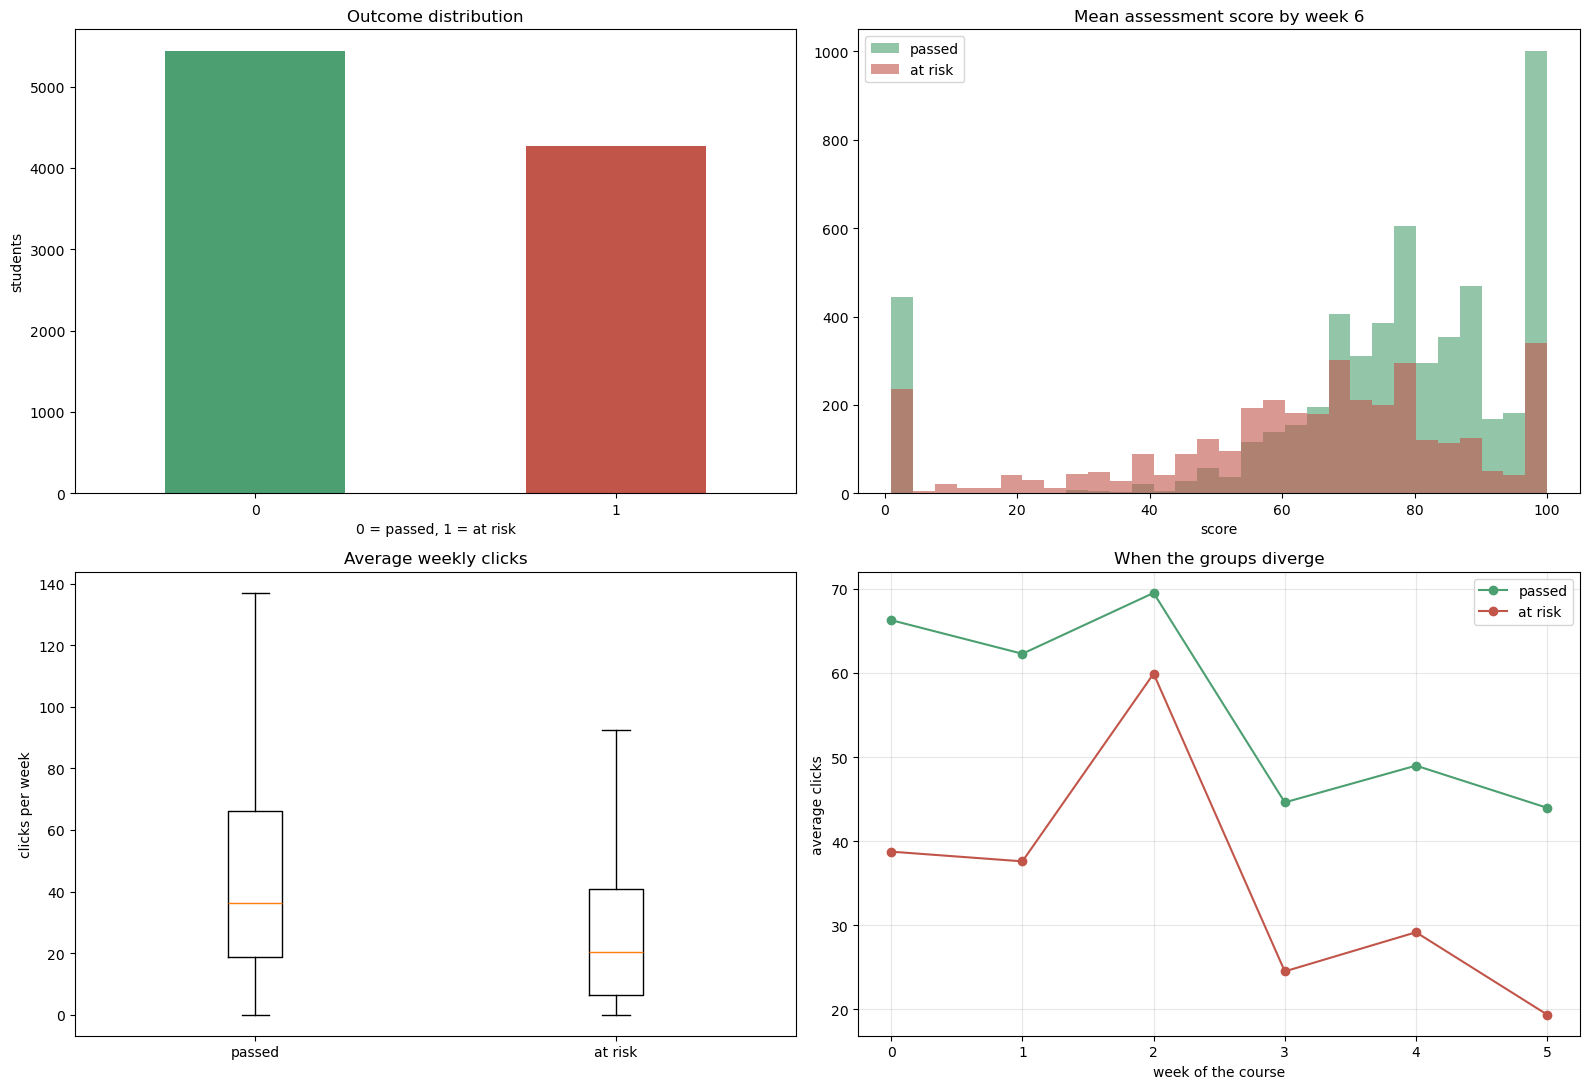

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.subplots_adjust(hspace=0.35, wspace=0.25)

df['at_risk'].value_counts().sort_index().plot(
    kind='bar', ax=axes[0, 0], color=['#4c9f70', '#c1554a'], rot=0)
axes[0, 0].set_title('Outcome distribution')
axes[0, 0].set_xlabel('0 = passed, 1 = at risk')
axes[0, 0].set_ylabel('students')

for value, color, label in [(0, '#4c9f70', 'passed'), (1, '#c1554a', 'at risk')]:
    sub = df[(df.at_risk == value) & (df.mean_score > 0)]['mean_score']
    axes[0, 1].hist(sub, bins=30, alpha=.6, color=color, label=label)
axes[0, 1].set_title('Mean assessment score by week 6')
axes[0, 1].set_xlabel('score')
axes[0, 1].legend()

data = [df[df.at_risk == 0]['avg_weekly_clicks'], df[df.at_risk == 1]['avg_weekly_clicks']]
axes[1, 0].boxplot(data, showfliers=False)
axes[1, 0].set_xticklabels(['passed', 'at risk'])
axes[1, 0].set_title('Average weekly clicks')
axes[1, 0].set_ylabel('clicks per week')

# The real divergence curve: week by week, not two points
merged = weekly.merge(df[KEY + ['at_risk']], on=KEY, how='inner')
curve = merged.groupby(['week', 'at_risk'])['total_clicks'].mean().unstack()
axes[1, 1].plot(curve.index, curve[0], marker='o', color='#4c9f70', label='passed')
axes[1, 1].plot(curve.index, curve[1], marker='o', color='#c1554a', label='at risk')
axes[1, 1].set_title('When the groups diverge')
axes[1, 1].set_xlabel('week of the course')
axes[1, 1].set_ylabel('average clicks')
axes[1, 1].legend()
axes[1, 1].grid(alpha=.3)

plt.tight_layout()
plt.savefig(OUT + 'eda_overview.png', dpi=120)
plt.show()

In [39]:
gap = (curve[0] - curve[1]) / curve[0] * 100
print('Gap between the groups, % of the passing group:')
print(gap.round(1).to_string())

Gap between the groups, % of the passing group:
week
0    41.5
1    39.6
2    13.8
3    45.1
4    40.5
5    55.9


### Findings

Write these into `docs/` — they are the deliverable of US5.

1. The classes are close to balanced: about 44 % at risk, no resampling needed.
2. **The two groups are already apart in week 0.** The gap does not build up
   slowly — students who will fail start the course less engaged.
3. Week 2 is an exception: both groups spike, probably before the first
   assessment, and the gap narrows to about 14 %. A prediction point placed
   there would work noticeably worse.
4. From week 3 the at-risk group falls away and the gap grows to 56 % by week 5.
5. Mean assessment score separates the groups well, but by week 6 only one or
   two items are due, so the activity features carry most of the signal.
6. Because the signal is there from week 1, **a prediction earlier than week 6
   is worth testing** — an earlier warning is worth more to the user. This
   goes into US7.